# Bank Marketing: Will the Client Subscribe? (Classification)
A quick end-to-end tour of a **supervised classification** project on a business problem.

## Data description
**Source:** UCI *Bank Marketing* dataset. It comes from phone marketing campaigns of a Portuguese bank (about 45,000 clients).

**Goal:** predict whether a client will subscribe to a term deposit (`y`: `yes` = 1, `no` = 0).

Each row is one client contacted by the bank. The columns are:

| Column | Type | Description |
|---|---|---|
| `age` | numeric | Age of the client |
| `job` | categorical | Type of job (admin., technician, retired, student...) |
| `marital` | categorical | Marital status (married, single, divorced) |
| `education` | categorical | Education level (primary, secondary, tertiary) |
| `default` | categorical | Does the client have credit in default? (yes/no) |
| `balance` | numeric | Average yearly account balance (in euros) |
| `housing` | categorical | Does the client have a housing loan? (yes/no) |
| `loan` | categorical | Does the client have a personal loan? (yes/no) |
| `contact` | categorical | Contact communication type (cellular, telephone) |
| `day_of_week` | numeric | Day of the last contact (values 1 to 31, so it is the day of the month) |
| `month` | categorical | Month of the last contact |
| `duration` | numeric | Duration of the last call, in seconds |
| `campaign` | numeric | Number of contacts made to this client during this campaign |
| `pdays` | numeric | Days since the client was last contacted in a previous campaign (-1 = never contacted) |
| `previous` | numeric | Number of contacts made before this campaign |
| `poutcome` | categorical | Outcome of the previous campaign (success, failure, other, unknown) |
| **`y`** | **target** | **Did the client subscribe to a term deposit? (yes/no)** |

## 1. Import libraries

In [ ]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay)

## 2. Load the data
The dataset is downloaded from the UCI repository (internet needed). The first line installs the `ucimlrepo` package (needed once, e.g. on Google Colab).

In [ ]:
# Install the package (needed once, e.g. on Google Colab)
!pip install -q ucimlrepo

from ucimlrepo import fetch_ucirepo

# Download the Bank Marketing dataset (id = 222)
bank = fetch_ucirepo(id=222)

# Join the features and the target column (y) into one DataFrame
df = pd.concat([bank.data.features, bank.data.targets], axis=1)

# Show the first 5 rows
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [ ]:
df["y"].value_counts()

,count
y,
0,39922
1,5289


## 3. Explore the data (EDA)
Each row is a client contacted by the bank. The column `y` tells us if the client subscribed.

In [ ]:
# Number of rows and columns
print("Shape:", df.shape)

# Column types and non-null counts
df.info()

Shape: (45211, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [ ]:
# Basic statistics for numeric columns
df.describe()

,age,balance,day_of_week,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [ ]:
# Count missing values per column
df.isnull().sum()

,0
age,0
job,288
marital,0
education,1857
default,0
balance,0
housing,0
loan,0
contact,13020
day_of_week,0


y
no     0.883
yes    0.117
Name: proportion, dtype: float64


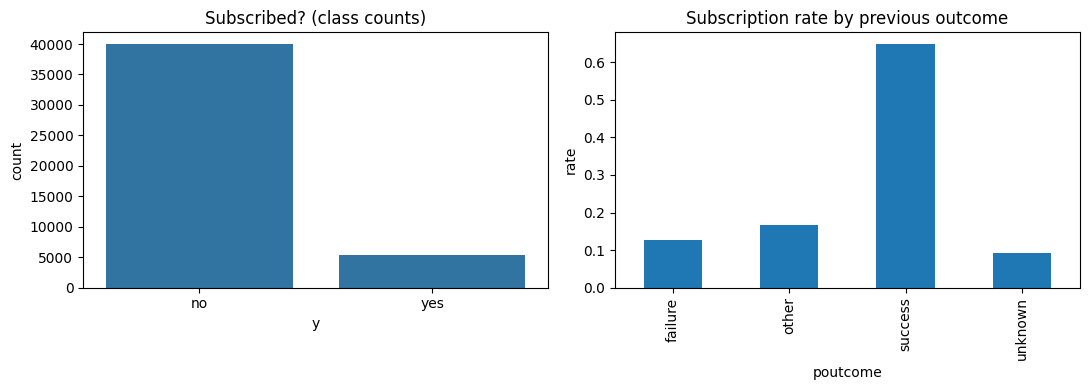

In [ ]:
# Look at the target: is it balanced?
print(df["y"].value_counts(normalize=True).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Number of clients per class
sns.countplot(x="y", data=df, ax=axes[0])
axes[0].set_title("Subscribed? (class counts)")

# Subscription rate by previous campaign outcome
rate = df.assign(target=(df["y"] == "yes").astype(int)).groupby(df["poutcome"].fillna("unknown"))["target"].mean()
rate.plot(kind="bar", ax=axes[1])
axes[1].set_title("Subscription rate by previous outcome")
axes[1].set_ylabel("rate")

plt.tight_layout()
plt.show()

**Important observation:** the classes are **imbalanced** (only about 1 client in 8 says yes). Accuracy alone will be misleading, so we will also look at recall, F1 and AUC.

### Prepare a copy for plotting
We keep the original `df` untouched and plot from a copy `eda`, where missing categories are shown as "unknown" and the target also exists as 0/1 (needed for averages and correlations).

In [ ]:
eda = df.copy()

# Categorical columns (everything that is text, except the target)
cat_features = eda.select_dtypes(include="object").columns.drop("y")

# Show missing categories as "unknown"
eda[cat_features] = eda[cat_features].fillna("unknown")

# Numeric version of the target: yes -> 1, no -> 0
eda["target"] = (eda["y"] == "yes").astype(int)

### Countplot: categorical features vs target
How many clients are in each category, split by yes / no?

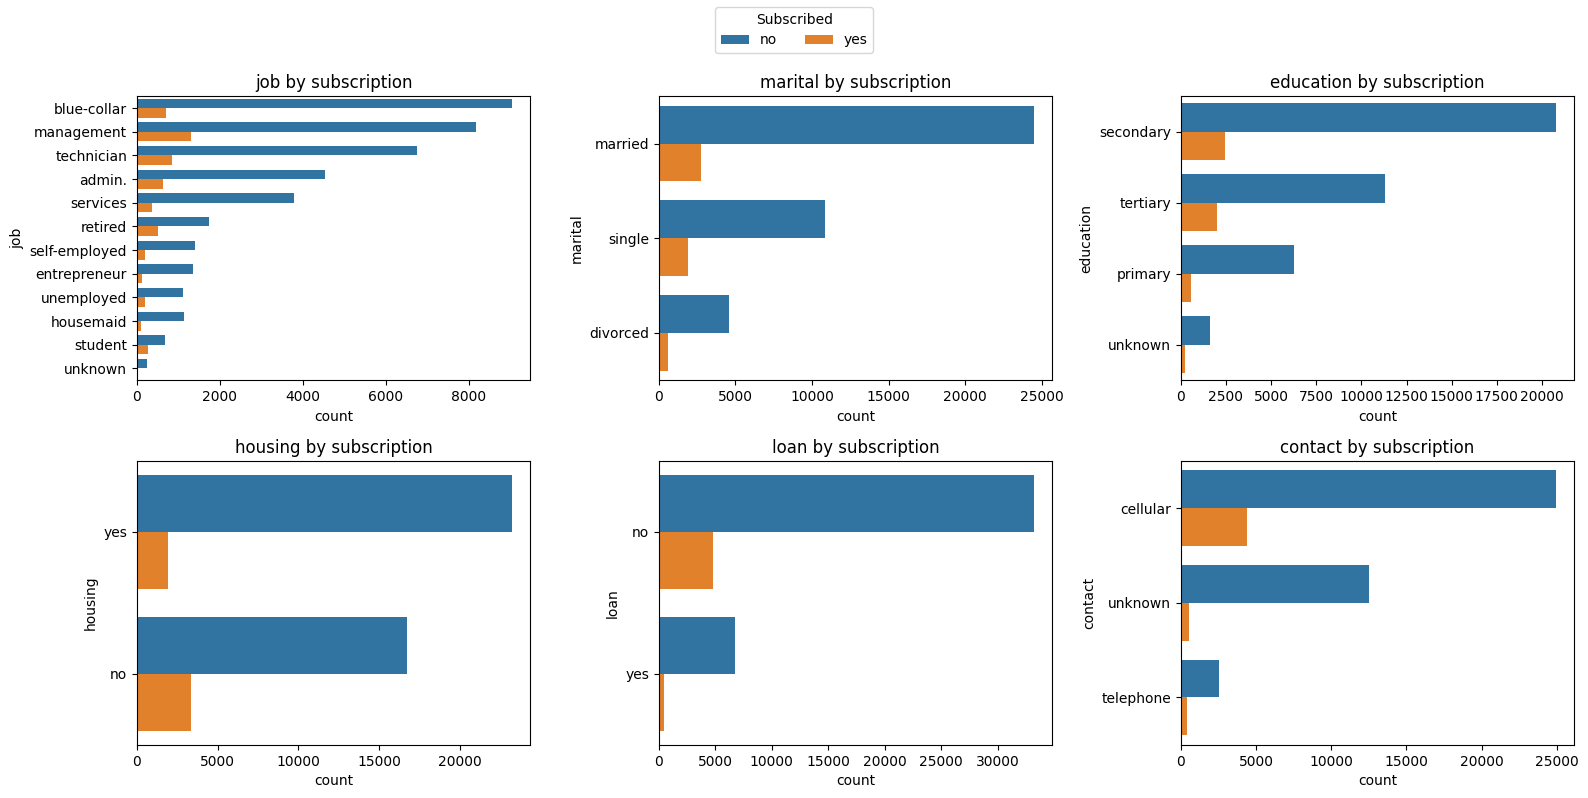

In [ ]:
cols = ["job", "marital", "education", "housing", "loan", "contact"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, cols):
    # y=col gives horizontal bars (easier to read long labels)
    sns.countplot(data=eda, y=col, hue="y", order=eda[col].value_counts().index, ax=ax)
    ax.set_title(f"{col} by subscription")
    # Keep the legend handles, then remove the legend inside each plot
    handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

# One shared legend for the whole figure
fig.legend(handles, labels, title="Subscribed", loc="upper center", ncol=2)
plt.tight_layout(rect=[0, 0, 1, 0.93])   # leave room at the top for the legend
plt.show()

### Bar plot: subscription rate
Counts can be misleading when groups have different sizes, so we plot the **rate** of yes (average of the 0/1 target) per group.

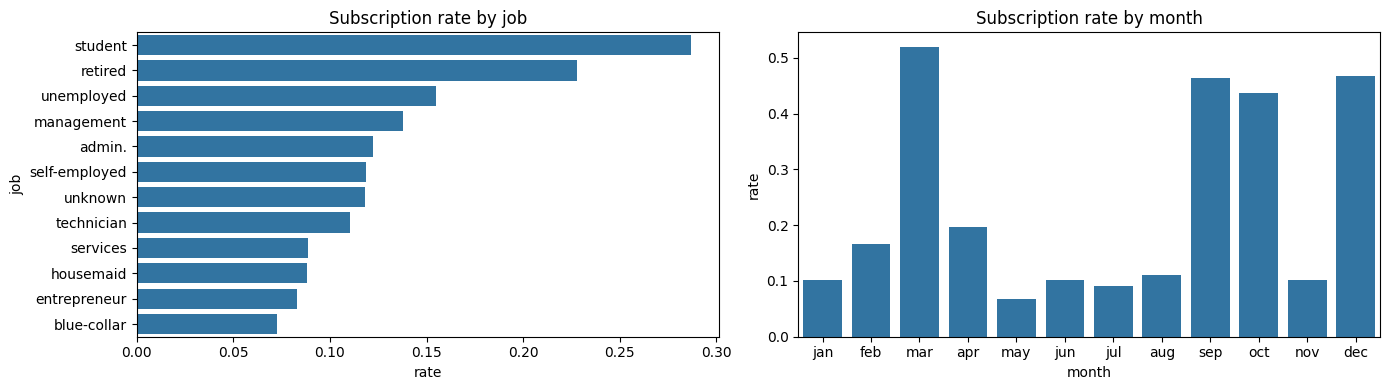

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Subscription rate by job (sorted from highest to lowest)
rate_job = eda.groupby("job")["target"].mean().sort_values(ascending=False)
sns.barplot(x=rate_job.values, y=rate_job.index, ax=axes[0])
axes[0].set_title("Subscription rate by job")
axes[0].set_xlabel("rate")

# Subscription rate by month (in calendar order)
months = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
rate_month = eda.groupby("month")["target"].mean().reindex(months).dropna()
sns.barplot(x=rate_month.index, y=rate_month.values, ax=axes[1])
axes[1].set_title("Subscription rate by month")
axes[1].set_ylabel("rate")

plt.tight_layout()
plt.show()

### Histograms: numeric features
What does the distribution of each numeric feature look like?

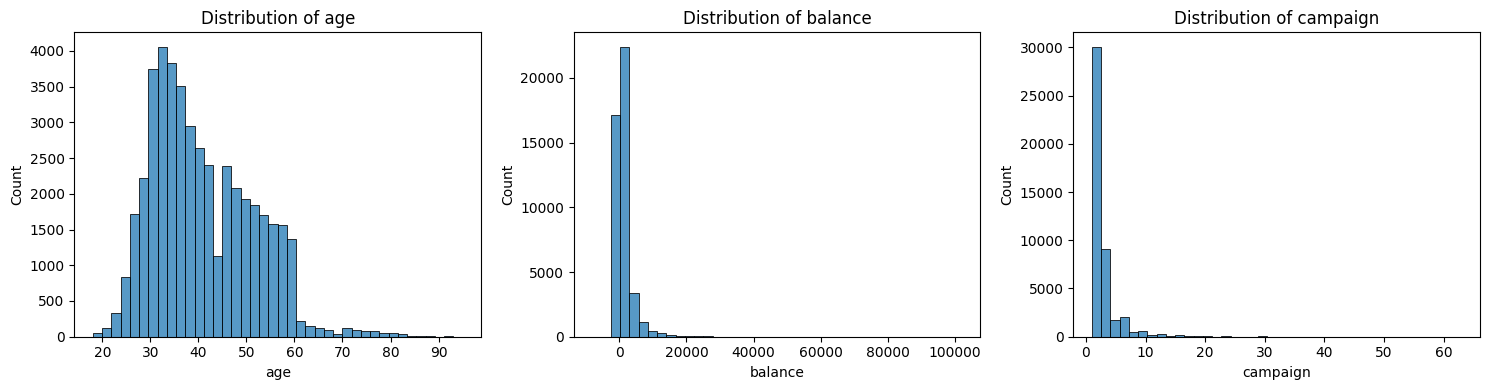

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["age", "balance", "campaign"]):
    sns.histplot(data=eda, x=col, bins=40, ax=ax)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

### Boxplot: numeric features vs target
Do clients who say yes look different from those who say no? (We hide the extreme outliers so the boxes stay readable.)

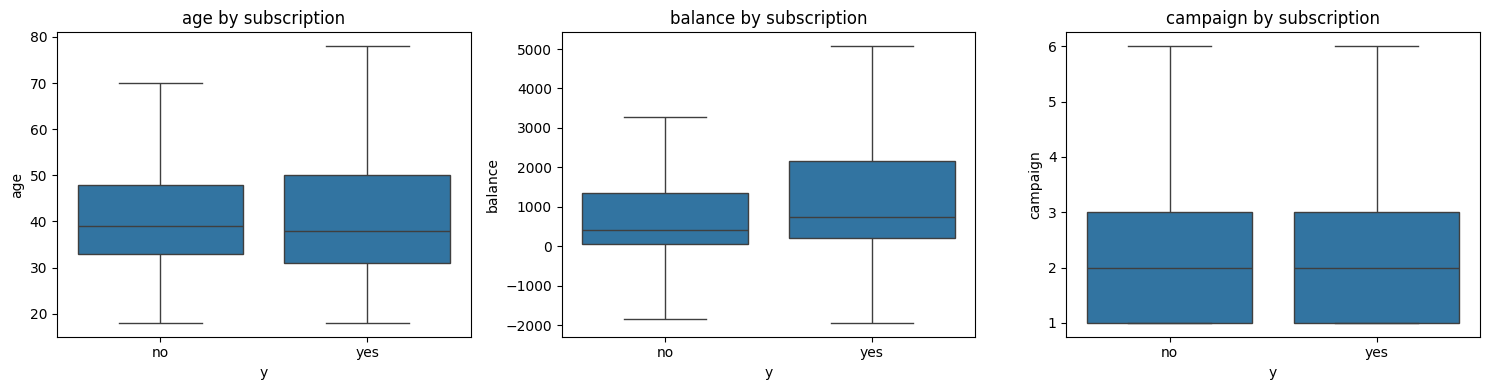

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["age", "balance", "campaign"]):
    sns.boxplot(data=eda, x="y", y=col, showfliers=False, ax=ax)
    ax.set_title(f"{col} by subscription")

plt.tight_layout()
plt.show()

### Correlation matrix
Correlation measures how two numeric columns move together (from -1 to +1). Look at the `target` row: which feature is the most related to subscription? You will see that `duration` stands out, which is exactly why we remove it later (data leakage).

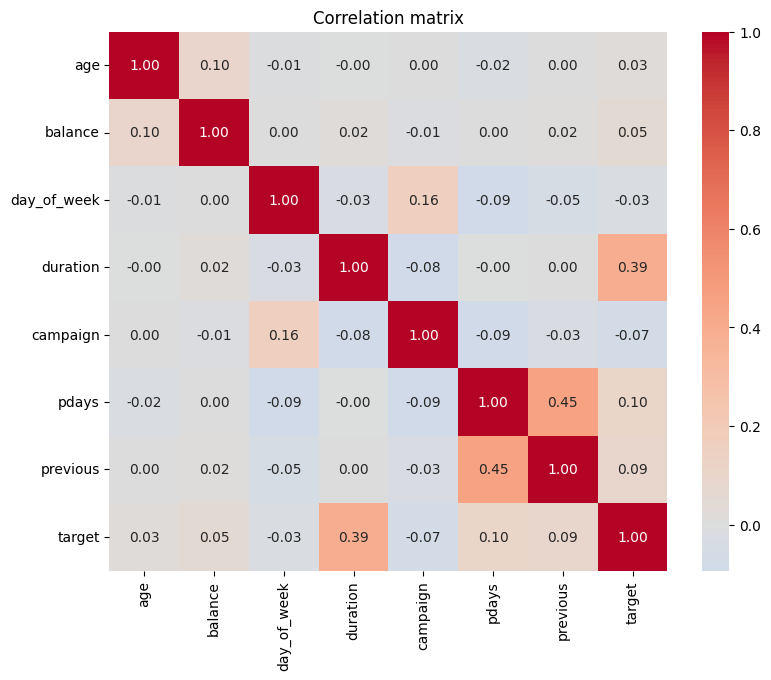

In [ ]:
# Correlation between all numeric columns (including the 0/1 target)
corr = eda.select_dtypes(include="number").corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

### Scatter plots
Two numeric features at a time, colored by the target. We draw a sample of 3000 clients to keep the plots fast and readable.

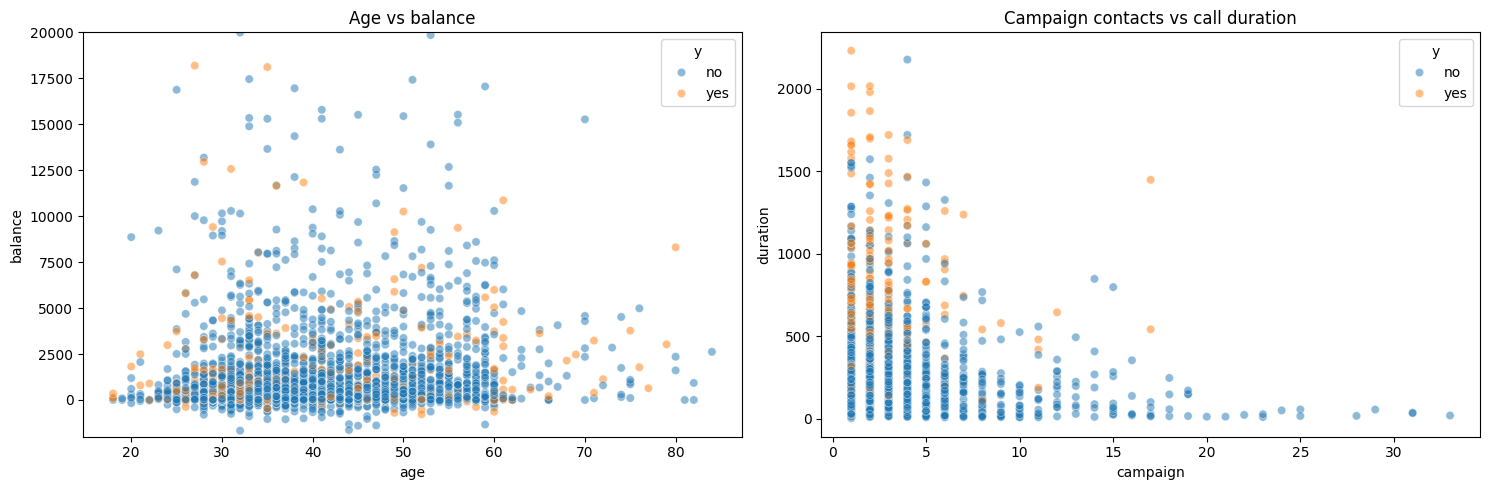

In [ ]:
sample = eda.sample(3000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Age vs balance
sns.scatterplot(data=sample, x="age", y="balance", hue="y", alpha=0.5, ax=axes[0])
axes[0].set_ylim(-2000, 20000)   # zoom in: a few clients have a huge balance
axes[0].set_title("Age vs balance")

# Number of contacts vs call duration
sns.scatterplot(data=sample, x="campaign", y="duration", hue="y", alpha=0.5, ax=axes[1])
axes[1].set_title("Campaign contacts vs call duration")

plt.tight_layout()
plt.show()

## 4. Clean the data
We handle missing values and remove a column that would cause **data leakage**.

In [ ]:
# Missing values in categorical columns become their own category "unknown"
cat_cols = df.select_dtypes(include="object").columns.drop("y")
df[cat_cols] = df[cat_cols].fillna("unknown")

# Drop 'duration' (length of the last call):
# it is only known AFTER the call, so it would not be available when predicting
df = df.drop(columns=["duration"])

# Convert the target to numbers: yes -> 1, no -> 0
df["y"] = (df["y"] == "yes").astype(int)

# Check that no missing values remain
print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


## 5. Encode categorical variables
Models need numbers, so we convert text columns (job, marital, education...) into 0/1 columns.

In [ ]:
# One-hot encoding (drop_first avoids redundant columns)
df = pd.get_dummies(df, columns=list(cat_cols), drop_first=True, dtype=int)

print("Shape after encoding:", df.shape)
df.head()

Shape after encoding: (45211, 42)


,age,balance,day_of_week,campaign,pdays,previous,y,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,58,2143,5,1,-1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
1,44,29,5,1,-1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
2,33,2,5,1,-1,0,0,0,1,0,...,0,0,0,1,0,0,0,0,0,1
3,47,1506,5,1,-1,0,0,1,0,0,...,0,0,0,1,0,0,0,0,0,1
4,33,1,5,1,-1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1


## 6. Split into train / test sets
The model learns on the **train** set and is judged on the unseen **test** set. `stratify=y` keeps the same yes/no proportion in both sets.

In [ ]:
# X = features, y = target
X = df.drop("y", axis=1)
y = df["y"]

# 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (36168, 41)
Test size: (9043, 41)


## 7. Scale the features
Put features on a similar scale (useful for Logistic Regression). We fit the scaler on the train set only.

In [ ]:
scaler = StandardScaler()

# Learn the scaling on train data, then apply it to both sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 8. Train the models
We compare a simple model (Logistic Regression) with a more powerful one (Random Forest). `class_weight="balanced"` tells both models to pay more attention to the rare class (the clients who say yes).

In [ ]:
# Model 1: Logistic Regression (uses scaled data)
log_reg = LogisticRegression(max_iter=1000, class_weight="balanced")
log_reg.fit(X_train_scaled, y_train)

# Model 2: Random Forest (does not need scaling)
rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced", n_jobs=-1)
rf.fit(X_train, y_train)

print("Both models trained!")

Both models trained!


## 9. Evaluate the models
We predict on the test set and measure how good the predictions are.

In [ ]:
# Predicted classes and predicted probabilities of 'yes'
y_pred_lr = log_reg.predict(X_test_scaled)
y_pred_rf = rf.predict(X_test)
proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]
proba_rf = rf.predict_proba(X_test)[:, 1]

# Baseline: a "model" that always answers 'no'
baseline = 1 - y_test.mean()
print(f"Baseline accuracy (always 'no'): {baseline:.3f}")

# Accuracy and AUC for both models
print(f"Logistic Regression -> accuracy: {accuracy_score(y_test, y_pred_lr):.3f} | AUC: {roc_auc_score(y_test, proba_lr):.3f}")
print(f"Random Forest       -> accuracy: {accuracy_score(y_test, y_pred_rf):.3f} | AUC: {roc_auc_score(y_test, proba_rf):.3f}")

Baseline accuracy (always 'no'): 0.883
Logistic Regression -> accuracy: 0.756 | AUC: 0.772
Random Forest       -> accuracy: 0.895 | AUC: 0.793


In [ ]:
# Precision, recall and F1-score for each model
# Focus on the 'Subscribed' line: recall = share of real subscribers we managed to find
print("=== Logistic Regression ===")
print(classification_report(y_test, y_pred_lr, target_names=["No", "Yes"]))

print("=== Random Forest ===")
print(classification_report(y_test, y_pred_rf, target_names=["No", "Yes"]))

=== Logistic Regression ===
              precision    recall  f1-score   support

          No       0.94      0.77      0.85      7985
         Yes       0.27      0.62      0.37      1058

    accuracy                           0.76      9043
   macro avg       0.60      0.70      0.61      9043
weighted avg       0.86      0.76      0.79      9043

=== Random Forest ===
              precision    recall  f1-score   support

          No       0.90      0.99      0.94      7985
         Yes       0.67      0.20      0.31      1058

    accuracy                           0.89      9043
   macro avg       0.79      0.59      0.63      9043
weighted avg       0.88      0.89      0.87      9043



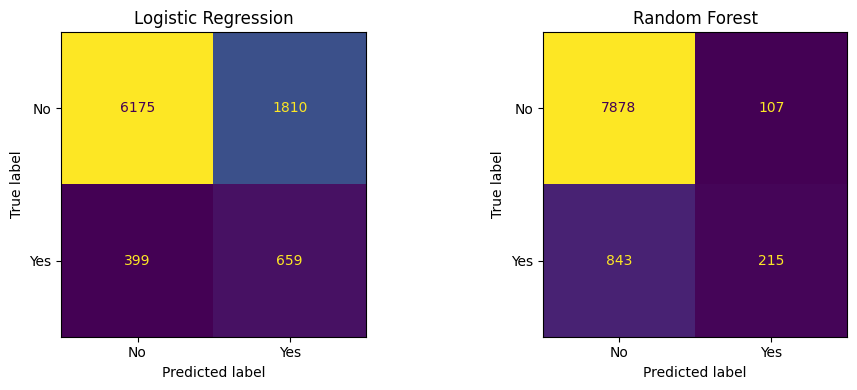

In [ ]:
# Confusion matrices: where does each model make mistakes?
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_lr), display_labels=["No", "Yes"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_rf), display_labels=["No", "Yes"]).plot(ax=axes[1], colorbar=False)
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

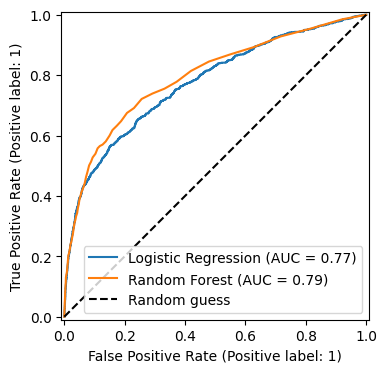

In [ ]:
# ROC curves: the closer to the top-left corner, the better
fig, ax = plt.subplots(figsize=(5, 4))
RocCurveDisplay.from_predictions(y_test, proba_lr, name="Logistic Regression", ax=ax)
RocCurveDisplay.from_predictions(y_test, proba_rf, name="Random Forest", ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.legend()
plt.show()

## 10. Compare and conclude

In [ ]:
# Summary table of results
results = pd.DataFrame({
    "Model": ["Always 'no' (baseline)", "Logistic Regression", "Random Forest"],
    "Accuracy": [baseline, accuracy_score(y_test, y_pred_lr), accuracy_score(y_test, y_pred_rf)],
    "AUC": [0.5, roc_auc_score(y_test, proba_lr), roc_auc_score(y_test, proba_rf)],
}).round(3)
results

,Model,Accuracy,AUC
0,Always 'no' (baseline),0.883,0.500
1,Logistic Regression,0.756,0.772
2,Random Forest,0.895,0.793


### Key takeaways
- A classification project follows a clear flow: **data → explore → clean → encode → split → train → evaluate**.
- With **imbalanced classes**, accuracy can be misleading: a model that always says "no" already scores high. Use recall, F1 and AUC too.
- Watch out for **data leakage**: we removed `duration` because it is only known after the call.
- Always evaluate on data the model has **never seen** (the test set).

**Going further (next sessions):** cross-validation, hyperparameter tuning, feature importance, choosing a decision threshold.